<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-classical-and-quantum-physics/blob/main/notebooks/lecture-05/lab-023-sk-without-labels.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning in Classical and Quantum Physics
2026/2027 <br>
**Author:** Marcin Płodzień <br>
**Lab:** 023 <br>
<hr/>

# Lab 023 — The SK spin glass without labels

Lab 032 introduced the Sherrington–Kirkpatrick (SK) spin glass: $N$ Ising spins, every pair coupled by a Gaussian random coupling
$J_{ij}\sim\mathcal N(0,J^2/N)$. Below $T_c=J$ the spins freeze in random directions. The magnetisation stays zero, a snapshot of the frozen phase
looks like noise, and the order is visible only when two **replicas** (independent copies with the same couplings) are compared through their overlap
$q=\frac1N\sum_is_i^as_i^b$. Lab 032 located the transition with the Binder cumulant of $q$: for the sizes $N=32,64,128$ the curves cross between
$T\approx0.87$ and $0.92$, with wide statistical intervals that contain $T_c=J$.

The transition at $T_c=J$ is continuous and of mean-field type, since every spin interacts with all others. It is not signalled by the
magnetisation, which is zero in both phases, nor by the ordinary magnetic susceptibility, but by the divergence of the spin-glass susceptibility
$\chi_{\rm SG}=\frac1N\sum_{ij}[\langle s_is_j\rangle^2]=1/(1-\beta^2J^2)$ as $T\to J$ from above ($\beta=1/T$). Below $T_c$ the replica symmetry is
broken (Parisi): the Boltzmann distribution splits into many valleys. In the Ising ferromagnet, by contrast, the magnetisation becomes non-zero
below $T_c$ and its own susceptibility diverges.

In the previous labs of this lecture the same two unsupervised methods, principal component analysis (PCA) and autoencoder anomaly detection,
found the magnetisation of the Ising model and both order parameters of the $J_1$–$J_2$ model directly from raw snapshots. The spin glass is a harder
test, for a reason we can state before computing anything: Lab 032 proved that single snapshots pooled over disorder samples are *exactly* uniformly
random strings of signs at every temperature. A method that receives single snapshots therefore has nothing to find, however powerful it is.
This notebook follows the same protocol as the previous ones. We first confirm that single snapshots carry no signal and see how a finite data set
can nevertheless fool us. We then give the methods the gauge-invariant input that Lab 032 identified, the **overlap field** $q_i=s_i^as_i^b$, and ask
what PCA and the autoencoder learn from it, where their signals sit relative to $T_c=J$, and how they change with $N$. Finally we run the same
detectors on the Mattis model, which has random signs but no frustration, as a control with a sharp, ferromagnet-like transition.

The units are those of Lab 032: $k_B=1$, $J=1$, temperatures in units of $J$. Square brackets $[\,\cdot\,]$ denote the average over disorder
samples, angular brackets $\langle\cdot\rangle$ the thermal average in one sample.

> **How to run this notebook in Google Colab**
> 1. Upload the notebook and the data files `data/sk_N32.npz`, `data/sk_N64.npz`, `data/sk_N128.npz` written by Lab 032 (run Lab 032 first if they are missing).
> 2. Run the cells in order with **Shift + Enter**. The packages `jax`, `flax`, `optax`, `numpy`, `scipy`, `scikit-learn` and `matplotlib` are pre-installed in Colab.
> 3. The notebook runs on the CPU in a few minutes; figures are written to `../beamer/figures/`.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"            # the whole notebook runs on the CPU
os.environ["CUDA_VISIBLE_DEVICES"] = ""        # never touch a GPU

import time, json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.special import gammaln

import jax
import jax.numpy as jnp
import optax
from flax import nnx
import sklearn
from sklearn.decomposition import PCA as SkPCA

print("JAX", jax.__version__, "| devices:", jax.devices(), "| scikit-learn", sklearn.__version__)

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
SIZE_COLORS = {32: "#9CC3E6", 64: UJBlue, 128: UJNavy}          # light -> dark: small N -> large N
SPIN_CMAP = ListedColormap(["#FFFFFF", UJNavy])
# common figure style: notebook figures about 10 in wide with 13-15 pt text
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15, "xtick.labelsize": 13,
                     "ytick.labelsize": 13, "legend.fontsize": 12, "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "lines.markersize": 5, "axes.titlecolor": UJNavy, "axes.titlelocation": "left", "legend.frameon": False})
FIG_W, FIG_H = 10.0, 3.8                        # two-panel figure size in inches
DATA, FIG = "data", "../beamer/figures"
os.makedirs(FIG, exist_ok=True)
savefig = lambda fig, name: fig.savefig(f"{FIG}/{name}", dpi=200, bbox_inches="tight")
NUMBERS = {}                                    # main numbers of the notebook, saved at the end
T_C = 1.0
SIZES = (32, 64, 128)
t_start = time.time()

JAX 0.11.0 | devices: [CpuDevice(id=0)] | scikit-learn 1.6.1


<hr/>
## 1. The data set and the reference result

Each file `data/sk_N{N}.npz` of Lab 032 holds Monte Carlo snapshots for $D$ disorder samples, produced by parallel tempering: for every sample,
copies of the system at a ladder of temperatures are simulated together and neighbouring copies exchange their configurations from time to time,
so that a configuration trapped in a valley at low temperature can escape through high temperatures and come back in another valley. The array `configs` has shape
`(D, 2, K, S, N)`: sample, replica $a$ or $b$, temperature, snapshot, spin, with $K=25$ temperatures $T=0.40,0.45,\dots,1.60$ and $S=32$ snapshots per
replica, separated by 64 Monte Carlo sweeps. The couplings of every sample are stored too, but we will not use them: the methods only see spins.
The array `q_int` holds $Nq_{ab}$ measured every 4 sweeps, 512 values per sample and temperature; we use it once, to reproduce the Binder-cumulant
result of Lab 032 that serves as the reference.

In [2]:
sk = {}
for N in SIZES:
    f = np.load(f"{DATA}/sk_N{N}.npz")
    sk[N] = dict(configs=f["configs"].astype(np.float32), q_int=f["q_int"], T=f["T"], D=int(f["D"]))
    print(f"N = {N:3d}: configs {f['configs'].shape} (D, replica, T, snapshot, spin),  q_int {f['q_int'].shape}")
T_GRID = sk[32]["T"]; K_T = len(T_GRID)
assert all(np.allclose(sk[N]["T"], T_GRID) for N in SIZES)
assert all(set(np.unique(sk[N]["configs"])) == {-1.0, 1.0} for N in SIZES)
print("temperatures:", T_GRID)

N =  32: configs (256, 2, 25, 32, 32) (D, replica, T, snapshot, spin),  q_int (256, 25, 512)


N =  64: configs (160, 2, 25, 32, 64) (D, replica, T, snapshot, spin),  q_int (160, 25, 512)


N = 128: configs (96, 2, 25, 32, 128) (D, replica, T, snapshot, spin),  q_int (96, 25, 512)


temperatures: [0.4  0.45 0.5  0.55 0.6  0.65 0.7  0.75 0.8  0.85 0.9  0.95 1.   1.05
 1.1  1.15 1.2  1.25 1.3  1.35 1.4  1.45 1.5  1.55 1.6 ]


The reference is the Binder cumulant of the overlap,
$$
g(T,N)=\frac12\left(3-\frac{[\langle q^4\rangle]}{[\langle q^2\rangle]^2}\right),
$$
which is $0$ for a Gaussian overlap distribution (paramagnet) and $1$ for two sharp peaks. Finite-size scaling makes $g(T_c,N)$ independent of $N$,
so the curves for different sizes cross at $T_c$. The functions below compute $g$ from per-sample moments, the crossing temperature of two curves by
linear interpolation, and a bootstrap over disorder samples: 200 resamplings of the $D$ samples with replacement, in which the two moments of a sample
always stay together because they are measured on the same sample. The same functions will be
applied later to quantities learned by the unsupervised methods, so that every result is compared with the reference in the same way.

In [3]:
def binder(m2, m4):
    """Binder cumulant from per-sample thermal moments m2, m4 of shape (D, K)."""
    return 0.5 * (3 - m4.mean(0) / m2.mean(0) ** 2)

def crossing(T, g1, g2, window=(0.6, 1.4)):
    """Temperature in the window where g1 - g2 changes sign (linear interpolation); NaN if it does not."""
    sel = (T >= window[0]) & (T <= window[1])
    T, dlt = T[sel], (g1 - g2)[sel]
    i = np.where(np.sign(dlt[:-1]) != np.sign(dlt[1:]))[0]
    if len(i) == 0:
        return np.nan
    i = i[0]
    return T[i] - dlt[i] * (T[i + 1] - T[i]) / (dlt[i + 1] - dlt[i])

def crossing_table(moments, n_boot=200, seed=7):
    """Crossings for the size pairs from moments[N] = (m2, m4); bootstrap over samples. Returns a dict of results."""
    rng = np.random.default_rng(seed)
    g_boot = {N: np.array([binder(*(m[idx] for m in moments[N]))
                           for idx in (rng.integers(0, len(moments[N][0]), len(moments[N][0])) for _ in range(n_boot))])
              for N in moments}
    out = {}
    for N1, N2 in ((32, 64), (64, 128), (32, 128)):
        c0 = crossing(T_GRID, binder(*moments[N1]), binder(*moments[N2]))
        cb = np.array([crossing(T_GRID, g_boot[N1][i], g_boot[N2][i]) for i in range(n_boot)])
        lo, hi = np.nanpercentile(cb, [16, 84])
        out[f"{N1}-{N2}"] = dict(T=round(float(c0), 3), lo=round(float(lo), 3), hi=round(float(hi), 3),
                                 no_crossing=int(np.isnan(cb).sum()))
        print(f"  N = {N1:3d} and {N2:3d}: crossing at T = {c0:.3f};  68% bootstrap interval [{lo:.3f}, {hi:.3f}];"
              f"  no crossing in {np.isnan(cb).sum()} of {n_boot} resamplings")
    return out, g_boot

mom_ref = {}
for N in SIZES:
    q = sk[N]["q_int"].astype(np.float64) / N                       # (D, K, 512)
    mom_ref[N] = ((q**2).mean(-1), (q**4).mean(-1))
print("reference: Binder cumulant of the measured overlaps q_int (Lab 032)")
NUMBERS["binder_ref"], _ = crossing_table(mom_ref)

reference: Binder cumulant of the measured overlaps q_int (Lab 032)
  N =  32 and  64: crossing at T = 0.870;  68% bootstrap interval [0.765, 0.933];  no crossing in 6 of 200 resamplings
  N =  64 and 128: crossing at T = 0.920;  68% bootstrap interval [0.816, 0.999];  no crossing in 4 of 200 resamplings
  N =  32 and 128: crossing at T = 0.894;  68% bootstrap interval [0.848, 0.938];  no crossing in 0 of 200 resamplings


The crossing temperatures are those of Lab 032: the pairwise crossings lie somewhat below $T_c=J$, and the 68% bootstrap intervals are broad,
of the order of $\pm0.05$ to $\pm0.1$, because the curves meet at a small angle; finite-size corrections for $N\le128$ also shift the crossings. Any unsupervised result in this notebook is judged against this table and against the exact value $T_c=J$.

Every observable of this notebook has two forms: its definition through the partition function, and the estimator that the code evaluates.
For one coupling sample $J$ the thermal average is $\langle A\rangle_J=Z_J^{-1}\sum_{\boldsymbol s}A(\boldsymbol s)\,e^{-\beta H_J(\boldsymbol s)}$ with
$Z_J=\sum_{\boldsymbol s}e^{-\beta H_J(\boldsymbol s)}$, and the disorder average over the $D$ samples of a data set is $[X]=\frac1D\sum_{d=1}^DX_{J_d}$.
The Monte Carlo data replace each thermal average by a mean over $n$ measurements of sample $d$, $\overline{x}_d=\frac1n\sum_{k=1}^nx_{d,k}$, where
$q_{d,k}$ is the overlap of the $k$-th replica pair; we write $\widehat{[q^p]}=\frac1D\sum_d\overline{q^p}_d$.

| observable | definition through $Z_J$ | estimator in the code |
|---|---|---|
| Edwards–Anderson parameter | $q_{\rm EA}=\frac1N\sum_i[\langle s_i\rangle_J^2]$ | through $\widehat{[q^2]}$ ($q^2=q_{\rm EA}^2$ in one valley) |
| overlap distribution | $P(q)=[\langle\delta(q-q_{ab})\rangle_J]$ | histogram of the $q_{d,k}$ of each sample, averaged over $d$ |
| spin-glass susceptibility | $\chi_{\rm SG}=N[\langle q^2\rangle_J]$ | $N\,\widehat{[q^2]}$ |
| Binder cumulant | $g=\frac12\big(3-[\langle q^4\rangle_J]/[\langle q^2\rangle_J]^2\big)$ | $\frac12\big(3-\widehat{[q^4]}/\widehat{[q^2]}^2\big)$ |
| reconstruction error | $\varepsilon(\boldsymbol q)=\frac1N\sum_i(q_i-\hat q_i)^2$ for one overlap field | $\bar\varepsilon=\frac1D\sum_d\overline{\varepsilon}_d$ over held-out samples |

In Section 1 the measurements are the $n=512$ overlaps recorded during the run; from Section 3 on they are the $n=1024$ snapshot pairs $(t,t')$.

Before turning to the learning methods we look at the physics content of the data. The first figure shows two replicas of one $N=128$ sample
and their overlap field at a low and a high temperature; the 128 spins are drawn as an $8\times16$ image only for display, since the SK model has no
lattice. The second shows the overlap distribution $P(q)$ (as a density, the probability of each value divided by the spacing $2/N$) above and
below $T_c$, and the third the spin-glass susceptibility and the Binder cumulant computed with the estimators of the table.

T = 0.4: mean of s^a +0.05, s^b +0.02, q +0.66
T = 1.5: mean of s^a -0.08, s^b +0.03, q +0.11


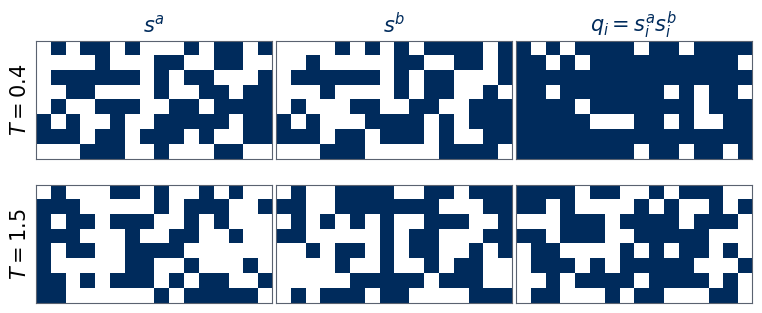

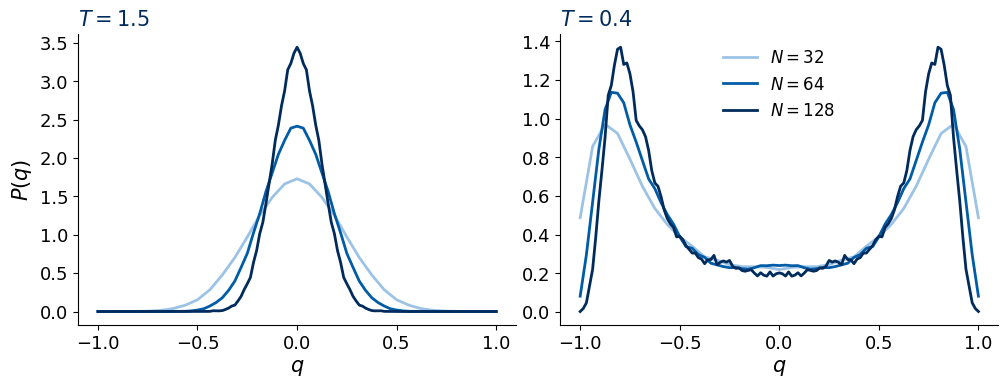

N =  32, T = 0.4: weight of P(q) at |q| < 0.1: 0.042
N =  64, T = 0.4: weight of P(q) at |q| < 0.1: 0.053
N = 128, T = 0.4: weight of P(q) at |q| < 0.1: 0.040


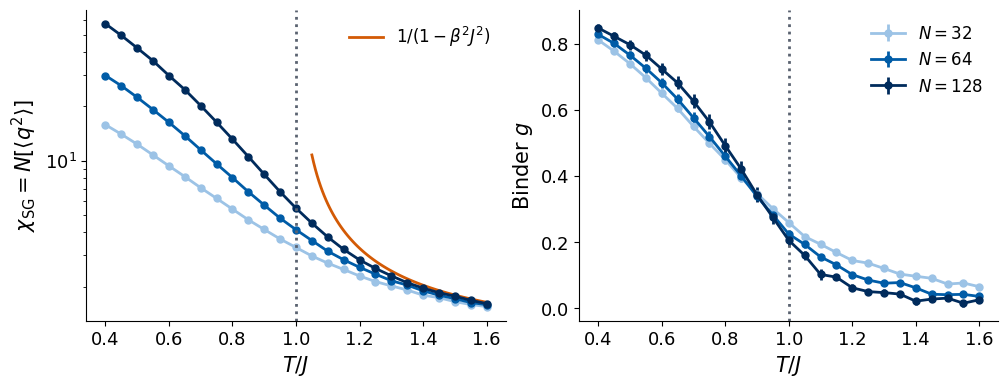

In [4]:
d = sk[128]["configs"]
fig, ax = plt.subplots(2, 3, figsize=(7.5, 3.4))
for r, T in enumerate((0.4, 1.5)):
    k = int(np.argmin(abs(T_GRID - T)))
    sa, sb = d[0, 0, k, -1], d[0, 1, k, -1]
    for c_, img in enumerate((sa, sb, sa * sb)):
        ax[r, c_].imshow(img.reshape(8, 16), cmap=SPIN_CMAP, vmin=-1, vmax=1)
        ax[r, c_].set_xticks([]); ax[r, c_].set_yticks([])
        for sp_ in ax[r, c_].spines.values(): sp_.set_visible(True); sp_.set_color(UJGray)
    ax[r, 0].set_ylabel(f"$T={T}$")
    print(f"T = {T}: mean of s^a {sa.mean():+.2f}, s^b {sb.mean():+.2f}, q {(sa * sb).mean():+.2f}")
for c_, name in enumerate(("$s^a$", "$s^b$", "$q_i=s^a_is^b_i$")):
    ax[0, c_].set_title(name, loc="center")
fig.tight_layout(pad=0.2); savefig(fig, "gen_sk_ml_phys_snap.png"); plt.show()

def pq_density(q_int, N, k):
    """Disorder-averaged, symmetrised P(q) as a density on q = -1, -1+2/N, ..., 1 from q_int (D, K, n)."""
    idx = (q_int[:, k].astype(np.int64) + N) // 2
    P = np.stack([np.bincount(row, minlength=N + 1) for row in idx]) / idx.shape[1]
    P = 0.5 * (P + P[:, ::-1]).mean(0)
    return np.linspace(-1, 1, N + 1), P * N / 2

fig, ax = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
for a, T in zip(ax, (1.5, 0.4)):
    k = int(np.argmin(abs(T_GRID - T)))
    for N in SIZES:
        qv, P = pq_density(sk[N]["q_int"], N, k)
        a.plot(qv, P, color=SIZE_COLORS[N], label=f"$N={N}$")
    a.set_title(f"$T={T}$"); a.set_xlabel("$q$")
ax[0].set_ylabel("$P(q)$"); ax[1].legend(loc="upper center")
fig.tight_layout(pad=0.3); savefig(fig, "gen_sk_ml_phys_Pq.png"); plt.show()
for N in SIZES:
    qv, P = pq_density(sk[N]["q_int"], N, 0)
    print(f"N = {N:3d}, T = 0.4: weight of P(q) at |q| < 0.1: {(P * 2 / N)[np.abs(qv) < 0.1].sum():.3f}")

rng_b = np.random.default_rng(7)
fig, ax = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
TT = np.linspace(1.05, 1.6, 100)
ax[0].plot(TT, 1 / (1 - 1 / TT**2), color=DSOrange, label=r"$1/(1-\beta^2J^2)$")
for N in SIZES:
    m2, m4 = mom_ref[N]
    boots = np.array([binder(m2[i], m4[i]) for i in (rng_b.integers(0, len(m2), len(m2)) for _ in range(200))])
    ax[0].plot(T_GRID, N * m2.mean(0), "o-", color=SIZE_COLORS[N])
    ax[1].errorbar(T_GRID, binder(m2, m4), yerr=boots.std(0), fmt="o-", color=SIZE_COLORS[N], label=f"$N={N}$")
ax[0].set_yscale("log"); ax[0].set_ylabel(r"$\chi_{\rm SG}=N[\langle q^2\rangle]$"); ax[0].legend(loc="upper right")
ax[1].set_ylabel("Binder $g$"); ax[1].legend(loc="upper right")
for a in ax:
    a.axvline(T_C, color=UJGray, ls=":"); a.set_xlabel("$T/J$")
fig.tight_layout(pad=0.3); savefig(fig, "gen_sk_ml_phys_binder.png"); plt.show()

The replicas look like noise at both temperatures, while their overlap field is mostly $+1$ at $T=0.4$. Above $T_c$ the overlap distribution
is a single peak that narrows as $N$ grows; at $T=0.4$ it has two peaks and a weight near $q=0$ that does not decrease with $N$ (printed above), the
signature of many valleys. The susceptibility follows $1/(1-\beta^2J^2)$ at high temperature and grows with $N$ near and below $T_c$, and the Binder
cumulants cross below $T=J$, as in the table of crossings.
<hr/>
## 2. Single snapshots

### 2.1 Consequences of the gauge symmetry

Lab 032 (Section 8.1) showed that the gauge transformation $s_i\to\tau_is_i$, $J_{ij}\to\tau_i\tau_jJ_{ij}$ leaves the distribution of the couplings
unchanged, so that the distribution of a single snapshot, pooled over disorder samples, is $[p_J(\boldsymbol s)]=2^{-N}$ at every temperature.
Two consequences matter for a data set. First, snapshots from *different* samples are independent, so a data set with **one snapshot per sample**
is a set of independent, uniformly random strings of signs, in the paramagnet and in the spin glass alike: every statistic computed from it has the
same distribution at every temperature. Second, snapshots of the *same* sample are not independent. Below $T_c$ two snapshots of one sample are
frozen in the same or related valleys, and their overlap is large. A data set with many snapshots per sample therefore contains replica pairs in
disguise, and a method can pick up the low-temperature structure from them. We test both statements with PCA.

### 2.2 PCA of single snapshots

PCA diagonalises the covariance matrix of the data. For a data matrix $X$ of shape `(M, N)` (one snapshot per row) with column means $\bar{\boldsymbol x}$,
$$
C=\frac{1}{M-1}(X-\bar{\boldsymbol x})^T(X-\bar{\boldsymbol x}),\qquad C\,\boldsymbol v_k=\lambda_k\boldsymbol v_k,\qquad \lambda_1\ge\lambda_2\ge\dots,
$$
where $\boldsymbol v_k$ are the principal components and $\lambda_k$ the variances along them. Since $N\le128$ is small, we diagonalise the
$N\times N$ matrix $C$ directly with `jnp.linalg.eigh`, which is much faster on the CPU than a singular value decomposition of the long data matrix.
The largest eigenvalue $\lambda_1$ is the variance of the data along the most important direction. For independent uniform strings $C$ is the identity
plus sampling noise, and $\lambda_1$ fluctuates around the upper edge of the Marchenko–Pastur distribution, $(1+\sqrt{N/M})^2$. Instead of relying on
this asymptotic formula we compare with the same computation on uniformly random strings of the same shape (40 draws, mean and two standard
deviations).

At every temperature we compute $\lambda_1$ for two data sets of the $N=128$ samples: one snapshot per sample ($M=D$), and all $2\times32$ snapshots
of every sample ($M=64D$).

In [5]:
@jax.jit
def pca_jax(X):
    """PCA by diagonalising the covariance matrix. X: (M, N).
    Returns the mean (N,), variances lambda_k in decreasing order (N,), components (N, N) with rows v_k."""
    mu = X.mean(0)
    Xc = X - mu
    C = Xc.T @ Xc / (X.shape[0] - 1)                     # (N, N) covariance matrix
    lam, V = jnp.linalg.eigh(C)                          # ascending eigenvalues, eigenvectors in columns
    return mu, lam[::-1], V[:, ::-1].T

def lambda1(X):
    return float(pca_jax(jnp.asarray(X, jnp.float32))[1][0])

def random_null(M, N, n_draw=40, seed=0):
    """Mean and standard deviation of lambda_1 for uniformly random +-1 strings of shape (M, N)."""
    rng = np.random.default_rng(seed)
    v = [lambda1(rng.choice([-1.0, 1.0], size=(M, N))) for _ in range(n_draw)]
    return np.mean(v), np.std(v)

N = 128; c = sk[N]["configs"]; D = sk[N]["D"]
lam_one = np.array([lambda1(c[:, 0, k, 0]) for k in range(K_T)])                    # one snapshot per sample, (D, N)
lam_all = np.array([lambda1(c[:, :, k].reshape(-1, N)) for k in range(K_T)])        # all snapshots, (64 D, N)
null_one, null_all = random_null(D, N), random_null(64 * D, N)
print(f"N = {N}, D = {D}")
print(f"one snapshot per sample: lambda_1 from {lam_one.min():.2f} to {lam_one.max():.2f};  random strings {null_one[0]:.2f} ± {null_one[1]:.2f}"
      f"  (Marchenko-Pastur edge {(1 + np.sqrt(N / D))**2:.2f})")
print(f"all snapshots          : lambda_1 = {lam_all[0]:.2f} at T = {T_GRID[0]},  {lam_all[-1]:.2f} at T = {T_GRID[-1]};"
      f"  random strings {null_all[0]:.2f} ± {null_all[1]:.2f}")
NUMBERS["single_pca"] = dict(N=N, lam_one_range=[round(float(lam_one.min()), 2), round(float(lam_one.max()), 2)],
                             null_one=[round(null_one[0], 2), round(null_one[1], 2)],
                             lam_all_lowT=round(float(lam_all[0]), 2), lam_all_highT=round(float(lam_all[-1]), 2),
                             null_all=[round(null_all[0], 2), round(null_all[1], 2)])

N = 128, D = 96
one snapshot per sample: lambda_1 from 4.23 to 4.72;  random strings 4.46 ± 0.15  (Marchenko-Pastur edge 4.64)
all snapshots          : lambda_1 = 3.35 at T = 0.4,  1.37 at T = 1.6;  random strings 1.30 ± 0.01


With one snapshot per sample, $\lambda_1$ stays inside the band of random strings at every temperature, as the gauge argument requires. With all
snapshots of each sample, $\lambda_1$ grows below $T\approx1$ and reaches about two and a half times its high-temperature value at $T=0.4$. This
growth is not a property of single snapshots: it comes from the fact that the data set contains 64 strongly correlated snapshots of each of only 96
samples. The leading directions are the frozen spin patterns of individual samples, and their weight decreases as the number of samples grows.
PCA is in effect measuring the overlap between snapshots of the same sample, which is the replica overlap without the name.

### 2.3 An autoencoder on single snapshots

The anomaly-detection protocol of the previous labs trains an autoencoder on one region and maps its reconstruction error. We use a dense
autoencoder, because the SK model has no lattice: the label $i$ of a spin carries no geometry, so convolutions have nothing to exploit. The encoder
maps $\boldsymbol s\in\{-1,1\}^N$ through a hidden layer of 64 rectified linear units (ReLU) to a latent vector $\boldsymbol z$, and the decoder maps $\boldsymbol z$
back through 64 ReLU units to $\hat{\boldsymbol s}\in[-1,1]^N$ with a final $\tanh$. The reconstruction error of one input is
$$
\varepsilon(\boldsymbol x)=\frac1N\sum_{i=1}^N(x_i-\hat x_i)^2 ,
$$
and the loss is its mean over a mini-batch of inputs, the mean squared error between input and reconstruction. It is minimised with Adam
(adaptive moment estimation), a gradient-descent method that scales the step of every parameter by running averages of its past gradients and
their squares, with learning rate $10^{-3}$. For speed the whole training epoch is compiled into one function
with `jax.lax.scan` over mini-batches. Every training set is augmented by the global flip $\boldsymbol x\to-\boldsymbol x$, a symmetry of the Hamiltonian.

A memorising network could reconstruct the snapshots of the samples it was trained on without learning anything general. We therefore split the
disorder samples into two halves (even and odd sample index) and evaluate on samples that the network has never seen. Two single-snapshot
autoencoders are trained on the even samples: one on the paramagnet ($T\ge1.3$, latent dimension 8), one on the frozen phase ($T\le0.6$, latent
dimension 16, enough to store frozen patterns).

In [6]:
class DenseAE(nnx.Module):
    """Dense autoencoder n_in -> hidden -> latent -> hidden -> n_in; output tanh (spins) or linear."""
    def __init__(self, n_in, latent, hidden=64, out="tanh", *, rngs):
        self.e1 = nnx.Linear(n_in, hidden, rngs=rngs); self.e2 = nnx.Linear(hidden, latent, rngs=rngs)
        self.d1 = nnx.Linear(latent, hidden, rngs=rngs); self.d2 = nnx.Linear(hidden, n_in, rngs=rngs)
        self.out = out
    def encode(self, x):
        return self.e2(nnx.relu(self.e1(x)))
    def __call__(self, x):
        y = self.d2(nnx.relu(self.d1(self.encode(x))))
        return jnp.tanh(y) if self.out == "tanh" else y

def train_ae(X, latent, epochs, hidden=64, out="tanh", batch=256, lr=1e-3, seed=0):
    """Train a DenseAE on X (M, n_in) with Adam; one compiled lax.scan per epoch. Returns the model and the loss per epoch."""
    X = jnp.asarray(X, jnp.float32)
    model = DenseAE(X.shape[1], latent, hidden, out, rngs=nnx.Rngs(seed))
    graph, params = nnx.split(model, nnx.Param)
    tx = optax.adam(lr); opt_state = tx.init(params)
    n_b = X.shape[0] // batch
    loss_fn = lambda p, x: jnp.mean((nnx.merge(graph, p)(x) - x) ** 2)

    @jax.jit
    def epoch(p, o, key):
        perm = jax.random.permutation(key, X.shape[0])[: n_b * batch].reshape(n_b, batch)   # (n_b, batch) indices
        def body(carry, idx):
            p, o = carry
            l, g = jax.value_and_grad(loss_fn)(p, X[idx])
            u, o = tx.update(g, o, p)
            return (optax.apply_updates(p, u), o), l
        (p, o), ls = jax.lax.scan(body, (p, o), perm)
        return p, o, ls.mean()

    key, hist = jax.random.PRNGKey(seed), []
    for _ in range(epochs):
        key, k = jax.random.split(key)
        params, opt_state, l = epoch(params, opt_state, k)
        hist.append(float(l))
    return nnx.merge(graph, params), np.array(hist)

@nnx.jit
def recon_error(model, x):
    """Reconstruction error per input, x: (M, n_in) -> (M,)."""
    return jnp.mean((model(x) - x) ** 2, axis=-1)

@nnx.jit
def encode(model, x):
    return model.encode(x)

def flip_augment(X):
    return np.concatenate([X, -X])

HIGH_T, LOW_T = T_GRID >= 1.3, T_GRID <= 0.6
def folds(D):
    """Two-fold split of the disorder samples: (train, test) index arrays by even / odd sample index."""
    i = np.arange(D)
    return [(i[i % 2 == f], i[i % 2 != f]) for f in (0, 1)]

In [7]:
t0 = time.time()
single_ae = {}
for N in SIZES:
    c = sk[N]["configs"]; tr, te = folds(sk[N]["D"])[0]
    m_hi, h_hi = train_ae(flip_augment(c[tr][:, :, HIGH_T].reshape(-1, N)), latent=8, epochs=30)
    m_lo, h_lo = train_ae(flip_augment(c[tr][:, :, LOW_T].reshape(-1, N)), latent=16, epochs=60)
    err = lambda m, idx: np.array([float(recon_error(m, jnp.asarray(c[idx][:, :, k].reshape(-1, N))).mean()) for k in range(K_T)])
    single_ae[N] = dict(hi_test=err(m_hi, te), lo_train=err(m_lo, tr), lo_test=err(m_lo, te))
    r = single_ae[N]
    print(f"N = {N:3d}: trained on T >= 1.3, held-out samples: error {r['hi_test'].min():.3f} .. {r['hi_test'].max():.3f};"
          f"  trained on T <= 0.6: training samples {r['lo_train'][0]:.3f} (T = 0.4) .. {r['lo_train'][-1]:.3f} (T = 1.6),"
          f" held-out samples {r['lo_test'].min():.3f} .. {r['lo_test'].max():.3f}")
print(f"training time {time.time() - t0:.0f} s")
NUMBERS["single_ae"] = {N: dict(hi_test=[round(float(single_ae[N]["hi_test"].min()), 3), round(float(single_ae[N]["hi_test"].max()), 3)],
                                lo_train_T04=round(float(single_ae[N]["lo_train"][0]), 3),
                                lo_test=[round(float(single_ae[N]["lo_test"].min()), 3), round(float(single_ae[N]["lo_test"].max()), 3)])
                        for N in SIZES}

N =  32: trained on T >= 1.3, held-out samples: error 0.451 .. 0.455;  trained on T <= 0.6: training samples 0.099 (T = 0.4) .. 0.291 (T = 1.6), held-out samples 0.314 .. 0.330


N =  64: trained on T >= 1.3, held-out samples: error 0.745 .. 0.751;  trained on T <= 0.6: training samples 0.342 (T = 0.4) .. 0.802 (T = 1.6), held-out samples 0.820 .. 0.829


N = 128: trained on T >= 1.3, held-out samples: error 0.923 .. 0.927;  trained on T <= 0.6: training samples 0.343 (T = 0.4) .. 0.975 (T = 1.6), held-out samples 0.985 .. 0.992
training time 152 s


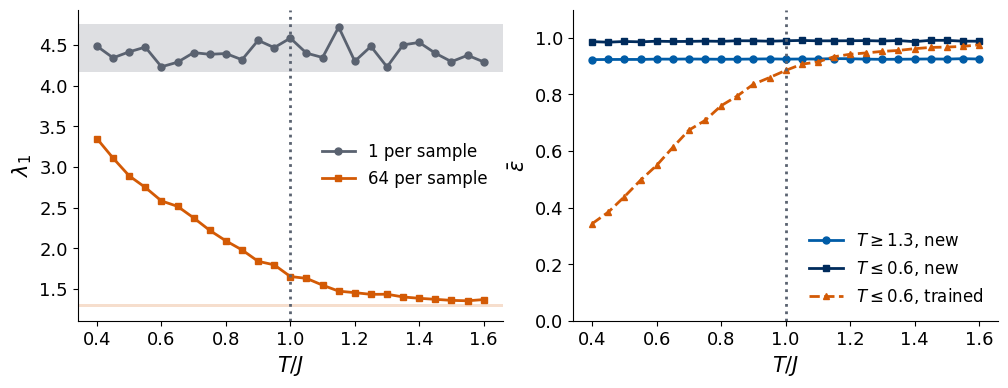

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
ax[0].axhspan(null_one[0] - 2 * null_one[1], null_one[0] + 2 * null_one[1], color=UJGray, alpha=0.2, lw=0)
ax[0].axhspan(null_all[0] - 2 * null_all[1], null_all[0] + 2 * null_all[1], color=DSOrange, alpha=0.2, lw=0)
ax[0].plot(T_GRID, lam_one, "o-", color=UJGray, label="1 per sample")
ax[0].plot(T_GRID, lam_all, "s-", color=DSOrange, label="64 per sample")
ax[0].set_ylabel(r"$\lambda_1$"); ax[0].legend(loc="center right")
r = single_ae[128]
ax[1].plot(T_GRID, r["hi_test"], "o-", color=UJBlue, label=r"$T\geq1.3$, new")
ax[1].plot(T_GRID, r["lo_test"], "s-", color=UJNavy, label=r"$T\leq0.6$, new")
ax[1].plot(T_GRID, r["lo_train"], "^--", color=DSOrange, label=r"$T\leq0.6$, trained")
ax[1].set_ylim(0, 1.1); ax[1].set_ylabel(r"$\bar\varepsilon$"); ax[1].legend(loc="lower right")
for a in ax:
    a.axvline(T_C, color=UJGray, ls=":"); a.set_xlabel("$T/J$")
fig.tight_layout(pad=0.3); savefig(fig, "gen_sk_ml_single.png"); plt.show()

The autoencoder trained on the paramagnet has an error that does not depend on temperature on held-out samples: it has learned nothing that
distinguishes the phases, because there is nothing to learn. (For $N=32$ the error is well below $1$: a latent vector of 8 numbers can store a
good part of a random string of 32 signs. The value is the same at every temperature.) The autoencoder trained on the frozen phase tells the
instructive story. On its own training samples its error is small at low temperature and grows towards $1$ as the temperature rises: it has stored
the frozen patterns of those particular samples. On held-out samples its error does not depend on temperature (the printed ranges are a few
thousandths wide for every size). The structure of a frozen snapshot is
specific to its sample, and nothing of it transfers to a new sample. A network that seems to detect the transition on the training samples is
detecting its own memory.
<hr/>
## 3. Overlap fields

### 3.1 The gauge-invariant input

For two replicas $a,b$ of the same sample the overlap field is
$$
q_i=s_i^a s_i^b\in\{-1,1\},\qquad i=1,\dots,N,\qquad q=\frac1N\sum_iq_i .
$$
It is invariant under the gauge transformation ($\tau_i^2=1$), and Lab 032 showed that the pooled distribution of pairs depends on the configurations
only through $\boldsymbol q$, and, because the SK ensemble is also symmetric under permutations of the spin labels, only on the number of $+1$ entries,
i.e. on $q$. Every $(\boldsymbol s^a,\boldsymbol s^b)$ pair of the data set gives one overlap field. Pairing snapshot $t$ of replica $a$ with snapshot $t'$ of
replica $b$ for all $t,t'$ gives $32\times32=1024$ fields per sample and temperature; the 32 simultaneous pairs $t=t'$ are used for training, all 1024
pairs for measurements. A field is a vector of length $N$, so the data matrices have shape `(pairs, N)`. The flip of one replica,
$\boldsymbol q\to-\boldsymbol q$, is an exact symmetry and is used for augmentation.

A consequence of the permutation symmetry should be kept in mind from the start. A function of one overlap field that does not depend on the order
of the spins can depend only on the number of $+1$ entries, that is, on $q$. Any permutation-invariant summary of one field is a function of $q$ alone.
A permutation-invariant network would therefore be forced to learn some function of $q$; we will see that the unconstrained dense networks arrive
there too.

In [9]:
def overlap_fields(c, idx, k, all_pairs=False):
    """Overlap fields of samples idx at temperature slot k. c: (D, 2, K, S, N).
    Simultaneous pairs: (len(idx) * S, N); all pairs (t, t'): (len(idx) * S * S, N)."""
    a, b = c[idx, 0, k], c[idx, 1, k]                                   # (n, S, N) each
    if all_pairs:
        return (a[:, :, None, :] * b[:, None, :, :]).reshape(-1, a.shape[-1])
    return (a * b).reshape(-1, a.shape[-1])

N = 128; c = sk[N]["configs"]
qf = overlap_fields(c, np.arange(2), 0, all_pairs=True)
print("all pairs of two samples at T = 0.4:", qf.shape, "  simultaneous pairs:", overlap_fields(c, np.arange(2), 0).shape)
print("q of the first 5 fields:", np.round(qf[:5].mean(1), 3))

all pairs of two samples at T = 0.4: (2048, 128)   simultaneous pairs: (64, 128)
q of the first 5 fields: [-0.625  0.719 -0.562  0.609 -0.234]


### 3.2 PCA of overlap fields

We pool the simultaneous-pair overlap fields of all samples and all 25 temperatures, add their mirror images $-\boldsymbol q$, and run PCA; the
method receives neither the temperature nor the sample index. Before looking at the result we can predict it. Because the pooled distribution is
symmetric under permutations of the labels and under $\boldsymbol q\to-\boldsymbol q$, the covariance matrix has the form
$C_{ij}=\delta_{ij}+(1-\delta_{ij})\,c$ with one number $c$. Its eigenvectors are the uniform vector $\boldsymbol v_1=(1,\dots,1)/\sqrt N$ and the
$N-1$ vectors orthogonal to it. The projection on the uniform vector is the overlap itself,
$$
z_1=\boldsymbol v_1\cdot\boldsymbol q=\sqrt N\,q,\qquad \lambda_{\rm uniform}=\boldsymbol v_1^TC\,\boldsymbol v_1=N\,\overline{q^2},
$$
where $\overline{q^2}$ is the mean of $q^2$ over the pooled data. Evaluated at a single temperature, $N[\langle q^2\rangle]$ is the spin-glass
susceptibility $\chi_{\rm SG}$ of Lab 032. The PCA implementation in JAX from Section 2 is checked against `sklearn.decomposition.PCA` on the same
data: the explained-variance ratios and the components must agree, the components up to a sign.

In [10]:
pca_q = {}
for N in SIZES:
    c = sk[N]["configs"]; D = sk[N]["D"]
    Xq = np.concatenate([overlap_fields(c, np.arange(D), k) for k in range(K_T)])     # (D * K * S, N)
    Xq = flip_augment(Xq)
    mu, lam, Vt = (np.asarray(a) for a in pca_jax(jnp.asarray(Xq)))
    v1 = Vt[0] * np.sign(Vt[0].sum())                                                  # fix the sign: positive sum
    pca_q[N] = dict(mu=mu, lam=lam, v1=v1, ratio=lam / lam.sum(), q2_pooled=float((Xq.mean(1) ** 2).mean()))
    print(f"N = {N:3d}: {Xq.shape[0]} fields;  lambda_1 = {lam[0]:.3f},  N * mean(q^2) = {N * pca_q[N]['q2_pooled']:.3f};"
          f"  explained variance PC1 {100 * lam[0] / lam.sum():.1f}%, PC2 {100 * lam[1] / lam.sum():.2f}%;"
          f"  sqrt(N) v_1: mean {np.sqrt(N) * v1.mean():.4f}, spread {np.sqrt(N) * v1.std():.4f}")

# the same PCA with scikit-learn, N = 128
sk_pca = SkPCA(n_components=5).fit(Xq)
r = pca_q[128]["ratio"][:5]
print("\nN = 128, explained variance ratio, JAX        :", np.round(r, 5))
print("N = 128, explained variance ratio, scikit-learn:", np.round(sk_pca.explained_variance_ratio_, 5))
print("|v_k(JAX) . v_k(scikit-learn)| for k = 1, 2, 3:",
      np.round([abs(np.dot(Vt[k], sk_pca.components_[k])) for k in range(3)], 6))
assert np.allclose(r, sk_pca.explained_variance_ratio_, atol=1e-5)
assert abs(np.dot(Vt[0], sk_pca.components_[0])) > 0.9999
NUMBERS["pca_q"] = {N: dict(lam1=round(float(pca_q[N]["lam"][0]), 3), ratio1=round(float(pca_q[N]["ratio"][0]), 4),
                            ratio2=round(float(pca_q[N]["ratio"][1]), 4),
                            v1_spread=round(float(np.sqrt(N) * pca_q[N]["v1"].std()), 4)) for N in SIZES}

N =  32: 409600 fields;  lambda_1 = 5.196,  N * mean(q^2) = 5.190;  explained variance PC1 16.2%, PC2 2.88%;  sqrt(N) v_1: mean 0.9993, spread 0.0375


N =  64: 256000 fields;  lambda_1 = 8.212,  N * mean(q^2) = 8.201;  explained variance PC1 12.8%, PC2 1.52%;  sqrt(N) v_1: mean 0.9992, spread 0.0394


N = 128: 153600 fields;  lambda_1 = 14.036,  N * mean(q^2) = 14.000;  explained variance PC1 11.0%, PC2 0.83%;  sqrt(N) v_1: mean 0.9986, spread 0.0529



N = 128, explained variance ratio, JAX        : [0.10966 0.00827 0.00823 0.00816 0.00808]
N = 128, explained variance ratio, scikit-learn: [0.10966 0.00827 0.00823 0.00816 0.00808]
|v_k(JAX) . v_k(scikit-learn)| for k = 1, 2, 3: [1. 1. 1.]


The first principal component is the uniform vector: the entries of $\sqrt N\,\boldsymbol v_1$ are $1$ up to a spread of a few percent, and
$\lambda_1$ equals $N\overline{q^2}$. The second component carries a variance comparable to all the others: the remaining spectrum is noise around the
value fixed by the trace, $\sum_k\lambda_k=N$. The higher components show some spread because a finite number of samples is not exactly permutation
symmetric, the same finite-sample effect as in Section 2.2, now much weaker. JAX and scikit-learn agree to the printed precision.

PCA has found the order parameter of the spin glass, the overlap, just as it found the magnetisation of the Ising model in Lab 019. The analogy is
exact: there the uniform vector projected the spins onto $\sqrt N m$, here it projects the overlap field onto $\sqrt N q$. The spins themselves
gave PCA nothing; the gauge-invariant pair input made the order linear again.

We now measure the projection $z_1=\boldsymbol v_1\cdot(\boldsymbol q-\bar{\boldsymbol q})$ on all 1024 pairs of every sample and temperature, and compute from it
the same Binder cumulant as in Section 1, with $z_1$ in place of $q$.

In [11]:
mom_pca, absz = {}, {}
for N in SIZES:
    c = sk[N]["configs"]; D = sk[N]["D"]
    v1, mu = jnp.asarray(pca_q[N]["v1"]), jnp.asarray(pca_q[N]["mu"])
    z = np.stack([np.asarray((jnp.asarray(overlap_fields(c, np.arange(D), k, True)) - mu) @ v1).reshape(D, -1)
                  for k in range(K_T)], axis=1)                                   # (D, K, 1024)
    mom_pca[N] = ((z**2).mean(-1), (z**4).mean(-1))
    absz[N] = np.abs(z).mean((0, 2)) / np.sqrt(N)
print("Binder cumulant of the PCA projection z_1")
NUMBERS["binder_pca"], g_boot_pca = crossing_table(mom_pca)

Binder cumulant of the PCA projection z_1
  N =  32 and  64: crossing at T = 0.869;  68% bootstrap interval [0.736, 0.960];  no crossing in 7 of 200 resamplings
  N =  64 and 128: crossing at T = 0.920;  68% bootstrap interval [0.792, 0.982];  no crossing in 3 of 200 resamplings
  N =  32 and 128: crossing at T = 0.903;  68% bootstrap interval [0.840, 0.944];  no crossing in 0 of 200 resamplings


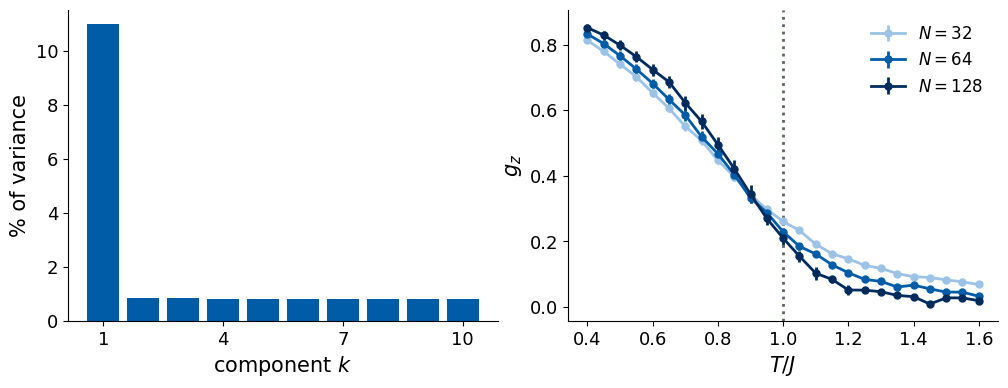

N = 128: sqrt(N) v_1 has mean 0.9986 and spread 0.0529
N =  32: [<|z_1|>]/sqrt(N) at T = 0.4: 0.650, at T = 1.6: 0.176
N =  64: [<|z_1|>]/sqrt(N) at T = 0.4: 0.636, at T = 1.6: 0.126
N = 128: [<|z_1|>]/sqrt(N) at T = 0.4: 0.629, at T = 1.6: 0.090


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
ax[0].bar(np.arange(1, 11), 100 * pca_q[128]["ratio"][:10], color=UJBlue)
ax[0].set_xlabel("component $k$"); ax[0].set_ylabel("% of variance"); ax[0].set_xticks([1, 4, 7, 10])
for N in SIZES:
    ax[1].errorbar(T_GRID, binder(*mom_pca[N]), yerr=g_boot_pca[N].std(0), fmt="o-", color=SIZE_COLORS[N], label=f"$N={N}$")
ax[1].axvline(T_C, color=UJGray, ls=":"); ax[1].set_xlabel("$T/J$"); ax[1].set_ylabel(r"$g_z$"); ax[1].legend(loc="upper right")
fig.tight_layout(pad=0.3); savefig(fig, "gen_sk_ml_pca.png"); plt.show()
print("N = 128: sqrt(N) v_1 has mean", round(float(np.sqrt(128) * pca_q[128]["v1"].mean()), 4),
      "and spread", round(float(np.sqrt(128) * pca_q[128]["v1"].std()), 4))
for N in SIZES:
    print(f"N = {N:3d}: [<|z_1|>]/sqrt(N) at T = 0.4: {absz[N][0]:.3f}, at T = 1.6: {absz[N][-1]:.3f}")

Because $z_1$ is $\sqrt N q$ up to the small spread of $\boldsymbol v_1$ and a negligible shift $\bar{\boldsymbol q}$, the projection reproduces the
overlap $[\langle|q|\rangle]$ (printed values) and the Binder cumulant of Lab 032, and the crossings agree with the reference table of Section 1 within the bootstrap
intervals (the small differences come from using the 1024 snapshot pairs instead of the 512 overlaps measured during the run). The linear method,
given the right input, reproduces the full finite-size-scaling analysis. It does not do better than the physicist's analysis, because it computes the
same quantity.

### 3.3 An autoencoder on overlap fields

The anomaly-detection protocol of Lab 019 trains on a well-structured phase. Here that is the frozen phase, $T\le0.6$, where the fields are mostly
$+1$ or mostly $-1$ with scattered exceptions. The autoencoder has a **latent dimension of one**, so it must compress each field into a single number;
everything else is as in Section 2.3. We use two folds: the network trained on the even samples is evaluated on the odd ones and vice versa, so
every sample is evaluated by a network that never saw it.

Before training we can predict the best such a network can do. If it encodes the overlap $q$ and outputs the constant vector $\hat q_i=q$, the error is
$$
\varepsilon=\frac1N\sum_i(q_i-q)^2=1-q^2,
$$
because $q_i^2=1$ and $\frac1N\sum_iq_i=q$. Positions of the exceptional spins are sample-specific and, as Section 2.3 showed, do not transfer to new
samples. We therefore expect a mean error $\bar\varepsilon(T)\approx1-[\langle q^2\rangle]$, an anomaly signal that is a known physical observable.

In [13]:
t0 = time.time()
ae_q = {}
for N in SIZES:
    c = sk[N]["configs"]; D = sk[N]["D"]
    E1, E2, Q2, Zq = np.zeros((D, K_T)), np.zeros((D, K_T)), np.zeros((D, K_T)), []
    for f, (tr, te) in enumerate(folds(D)):
        X_tr = np.concatenate([overlap_fields(c, tr, k) for k in np.where(LOW_T)[0]])
        model, hist = train_ae(flip_augment(X_tr), latent=1, epochs=60, seed=f)
        for k in range(K_T):
            X = overlap_fields(c, te, k, all_pairs=True)                           # (len(te) * 1024, N)
            e = np.asarray(recon_error(model, jnp.asarray(X))).reshape(len(te), -1)
            q = X.mean(1).reshape(len(te), -1)
            E1[te, k], E2[te, k], Q2[te, k] = e.mean(1), (e**2).mean(1), (q**2).mean(1)
            if f == 0 and N == 128 and k in (0, 8, 24):
                z = np.asarray(encode(model, jnp.asarray(X)))[:, 0]
                Zq.append((T_GRID[k], X.mean(1)[:4000], e.ravel()[:4000], z[:4000]))
    ae_q[N] = dict(err=E1.mean(0), q2=Q2.mean(0), E1=E1, Q2=Q2, scatter=Zq if N == 128 else None)
    dev = np.abs(E1.mean(0) - (1 - Q2.mean(0)))
    print(f"N = {N:3d}: mean error at T = 0.4 {E1.mean(0)[0]:.3f} (1 - [q^2] = {1 - Q2.mean(0)[0]:.3f}),"
          f"  at T = 1.6 {E1.mean(0)[-1]:.3f} ({1 - Q2.mean(0)[-1]:.3f});  largest |error - (1 - [q^2])| over T: {dev.max():.4f}")
print(f"training and evaluation time {time.time() - t0:.0f} s")

for T_s, q_s, e_s, z_s in ae_q[128]["scatter"]:
    print(f"N = 128, T = {T_s}: correlation of the latent variable with q: {np.corrcoef(z_s, q_s)[0, 1]:+.4f},"
          f"  rms deviation of the error from 1 - q^2: {np.sqrt(np.mean((e_s - (1 - q_s**2))**2)):.4f}")

# temperature where the mean error changes fastest (midpoint of the steepest grid step)
T_mid = 0.5 * (T_GRID[1:] + T_GRID[:-1])
T_steep = {N: float(T_mid[np.argmax(np.diff(ae_q[N]["err"]))]) for N in SIZES}
print("temperature of the steepest change of the mean error:", T_steep)
NUMBERS["ae_q"] = {N: dict(err_T04=round(float(ae_q[N]["err"][0]), 3), err_T16=round(float(ae_q[N]["err"][-1]), 3),
                           max_dev_from_1mq2=round(float(np.abs(ae_q[N]["err"] - 1 + ae_q[N]["q2"]).max()), 4),
                           T_steepest=round(T_steep[N], 3)) for N in SIZES}
NUMBERS["ae_q_latent_corr_N128"] = [round(float(np.corrcoef(z, q)[0, 1]), 4) for _, q, _, z in ae_q[128]["scatter"]]

N =  32: mean error at T = 0.4 0.507 (1 - [q^2] = 0.506),  at T = 1.6 0.950 (0.951);  largest |error - (1 - [q^2])| over T: 0.0014


N =  64: mean error at T = 0.4 0.536 (1 - [q^2] = 0.534),  at T = 1.6 0.976 (0.975);  largest |error - (1 - [q^2])| over T: 0.0027


N = 128: mean error at T = 0.4 0.555 (1 - [q^2] = 0.552),  at T = 1.6 0.990 (0.987);  largest |error - (1 - [q^2])| over T: 0.0043
training and evaluation time 108 s
N = 128, T = 0.4: correlation of the latent variable with q: +0.9964,  rms deviation of the error from 1 - q^2: 0.0085
N = 128, T = 0.8: correlation of the latent variable with q: +0.9936,  rms deviation of the error from 1 - q^2: 0.0109
N = 128, T = 1.6: correlation of the latent variable with q: +0.9415,  rms deviation of the error from 1 - q^2: 0.0077
temperature of the steepest change of the mean error: {32: 0.475, 64: 0.42500000000000004, 128: 0.475}


The printed numbers confirm the prediction. For each pair the error lies on the parabola $1-q^2$, and the mean error follows
$1-[\langle q^2\rangle]$ at every temperature, with a largest deviation below $0.005$ for every size. The latent variable is strongly correlated with $q$:
close to $1$ at low temperature, somewhat less at $T=1.6$, where all overlaps are small and the error hardly depends on them. Without being told, the
network has learned the overlap, and its reconstruction error is one minus the square of the overlap.

This fixes where the anomaly signal can sit. In the thermodynamic limit the Edwards–Anderson order parameter grows linearly below $T_c$,
$q_{\rm EA}\approx1-T/J$ (Lab 032, Section 4.6), so $q^2$ starts quadratically and the error has no kink at $T_c$. The steepest change of the mean error
lies between $T=0.42$ and $0.48$ for all three sizes (printed above), far below $T_c=J$, and it does not move towards $T_c$ as $N$ grows. This is different from the
Ising model (Lab 019), where the magnetisation rises steeply below $T_c$ and the steepest change of the error converged to $T_c$. Locating $T_c$ from
the learned overlap requires finite-size scaling, which we did in Section 3.2 with the PCA projection.

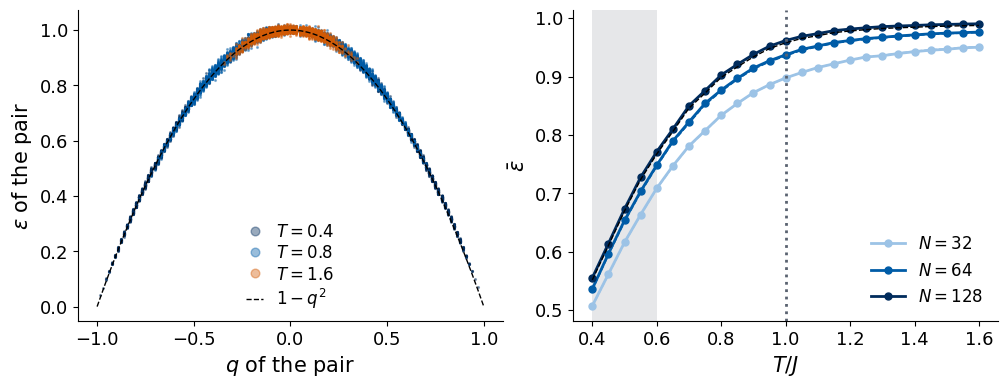

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
qq = np.linspace(-1, 1, 200)
for (T_s, q_s, e_s, z_s), col in zip(ae_q[128]["scatter"], (UJNavy, UJBlue, DSOrange)):
    ax[0].plot(q_s, e_s, ".", ms=2.5, alpha=0.4, color=col, label=f"$T={T_s}$")
ax[0].plot(qq, 1 - qq**2, "k--", lw=1, label="$1-q^2$")
ax[0].set_xlabel("$q$ of the pair"); ax[0].set_ylabel(r"$\varepsilon$ of the pair")
ax[0].legend(loc="lower center", markerscale=5, handlelength=1.0, borderpad=0.1, labelspacing=0.2)
for N in SIZES:
    ax[1].plot(T_GRID, ae_q[N]["err"], "o-", color=SIZE_COLORS[N], label=f"$N={N}$")
    ax[1].plot(T_GRID, 1 - ae_q[N]["q2"], "--", lw=1, color="k" if N == 128 else SIZE_COLORS[N])
ax[1].axvspan(T_GRID.min(), 0.6, color=UJGray, alpha=0.15, lw=0)
ax[1].axvline(T_C, color=UJGray, ls=":"); ax[1].set_xlabel("$T/J$"); ax[1].set_ylabel(r"$\bar\varepsilon$")
ax[1].legend(loc="lower right")
fig.tight_layout(pad=0.3); savefig(fig, "gen_sk_ml_ae.png"); plt.show()

### 3.4 Anomalies at the level of the overlap distribution

The single-field autoencoder can only learn $q$. The physics of the spin glass is richer: below $T_c$ the overlap distribution $P_J(q)$ of each sample
is broad, with weight between its peaks, and it differs from sample to sample. To let a network see this, we give it one input vector per sample and
temperature: the histogram of $|q|$ over the 1024 pairs, in 16 bins of width $1/16$ on $[0,1]$. The histogram is invariant under permutations of the
spins and of the snapshots, and it is the natural input when the object of interest is a distribution. The input has shape `(16,)`, the data set has
`(D, K, 16)`.

The anomaly detector is trained on the paramagnet, $T\ge1.3$, where every $P_J(q)$ is a narrow Gaussian around $0$ and the hypothesis "nothing
happens here" is safe. The autoencoder has a hidden layer of 32 units, a latent dimension of 2, and a linear output. As anomaly score we use the error in
units of its spread on the training data,
$$
a(\text{sample},T)=\frac{\varepsilon-\mu_{\rm train}}{\sigma_{\rm train}},
$$
evaluated, as before, on held-out samples with two folds. A score above $3$ means that the histogram is unlike any typical paramagnetic histogram.

In [15]:
def abs_q_histograms(c, n_bins=16):
    """Histogram of |q| over all S*S pairs, for every sample and temperature: (D, K, n_bins)."""
    D, _, K, S, N = c.shape
    H = np.zeros((D, K, n_bins))
    for k in range(K):
        q = np.einsum("dsi,dti->dst", c[:, 0, k], c[:, 1, k]).reshape(D, -1) / N         # (D, S*S)
        idx = np.minimum((np.abs(q) * n_bins).astype(int), n_bins - 1)
        H[:, k] = np.stack([(idx == b).mean(1) for b in range(n_bins)], axis=1)
    return H

def histogram_anomaly(H, seed=0):
    """Two-fold anomaly score of per-sample histograms H (D, K, n_bins); detector trained on T >= 1.3. Returns (D, K)."""
    D, K, n_b = H.shape
    score = np.zeros((D, K))
    for f, (tr, te) in enumerate(folds(D)):
        X_tr = H[tr][:, HIGH_T].reshape(-1, n_b)
        model, _ = train_ae(X_tr, latent=2, epochs=400, hidden=32, out="linear", batch=64, seed=seed + f)
        e_tr = np.asarray(recon_error(model, jnp.asarray(X_tr)))
        e = np.asarray(recon_error(model, jnp.asarray(H[te].reshape(-1, n_b)))).reshape(len(te), K)
        score[te] = (e - e_tr.mean()) / e_tr.std()
    return score

def onset(T, s, level):
    """Highest temperature at which the mean score s(T) reaches `level`, scanning down from high T (linear interpolation)."""
    above = np.where(s >= level)[0]
    if len(above) == 0:
        return np.nan
    i = above.max()
    if i == len(T) - 1:
        return T[-1]
    return T[i] + (level - s[i]) * (T[i + 1] - T[i]) / (s[i + 1] - s[i])

t0 = time.time()
hist_sk, score_sk = {}, {}
for N in SIZES:
    hist_sk[N] = abs_q_histograms(sk[N]["configs"])
    score_sk[N] = histogram_anomaly(hist_sk[N])
    s = score_sk[N].mean(0)
    print(f"N = {N:3d}: mean score at T = 1.6: {s[-1]:+.2f}, T = 1.2: {s[16]:.1f}, T = 1.0: {s[12]:.1f}, T = 0.4: {s[0]:.0f};"
          f"  score reaches 3 at T = {onset(T_GRID, s, 3):.3f}, 10 at T = {onset(T_GRID, s, 10):.3f}")
print(f"time {time.time() - t0:.0f} s")
NUMBERS["hist_onset"] = {N: dict(score3=round(float(onset(T_GRID, score_sk[N].mean(0), 3)), 3),
                                 score10=round(float(onset(T_GRID, score_sk[N].mean(0), 10)), 3)) for N in SIZES}

N =  32: mean score at T = 1.6: +0.03, T = 1.2: 0.6, T = 1.0: 3.2, T = 0.4: 434;  score reaches 3 at T = 1.007, 10 at T = 0.882


N =  64: mean score at T = 1.6: +0.02, T = 1.2: 0.7, T = 1.0: 12.2, T = 0.4: 471;  score reaches 3 at T = 1.094, 10 at T = 1.017


N = 128: mean score at T = 1.6: +0.02, T = 1.2: 1.1, T = 1.0: 48.7, T = 0.4: 424;  score reaches 3 at T = 1.167, 10 at T = 1.103
time 26 s


The score rises from zero well above $T_c$, and the temperature at which it reaches a given level *increases* with $N$ (printed above): for the
largest size the detector raises the alarm at the highest temperature. This is not a failure of the network; it is what the physics says. Above $T_c$
the width of $P_J(q)$ is set by the spin-glass susceptibility, $[\langle q^2\rangle]=\chi_{\rm SG}/N$ with $\chi_{\rm SG}=1/(1-\beta^2J^2)$, which grows
continuously as $T$ decreases towards $J$. The detector notices this growth as soon as it is larger than the sample-to-sample noise of the training
histograms, and that noise decreases as the histograms become more precise. An anomaly onset is therefore not a transition temperature: it depends on
the threshold, on the training window, and on the statistical resolution of the data. A mean-field transition, approached by a smooth growth of
fluctuations on both sides, gives an autoencoder no sharp edge to find.
<hr/>
## 4. The Mattis model as a control

Mattis couplings $J_{ij}=\frac JN\xi_i\xi_j$ with random fixed signs $\xi_i=\pm1$ look as random as SK couplings, but Lab 032 (Section 7) showed that the
gauge transformation $\sigma_i=\xi_is_i$ turns the model into the Curie–Weiss ferromagnet. This gives an exact sampler. In the Curie–Weiss model the energy
depends only on the magnetisation $M=\sum_i\sigma_i$, so the probability of $M$ is
$$
P(M)\propto\binom{N}{(N+M)/2}\exp\!\left[\frac{\beta J}{2N}\left(M^2-N\right)\right],
$$
and given $M$ all configurations with that magnetisation are equally likely. We draw $M$ from $P(M)$, place its $(N+M)/2$ up-spins at random positions,
and multiply by $\xi$ to obtain an exact equilibrium Mattis snapshot, with no Monte Carlo and no equilibration question. The overlap field of two
replicas is $s_i^as_i^b=\sigma_i^a\sigma_i^b$, independent of $\xi$: the hidden pattern drops out, exactly as the couplings drop out for the SK overlap
field. We generate a data set with the same shape as the SK data and check the sampler against the exact moment
$\langle\sigma_i\sigma_j\rangle=(\langle M^2\rangle-N)/(N(N-1))$ for $i\neq j$.

In [16]:
def cw_probabilities(N, T):
    """Exact P(M) of the Curie-Weiss model, M = 2 n_up - N, for J = 1: array (N + 1,) over n_up = 0..N."""
    n = np.arange(N + 1); M = 2 * n - N
    logw = gammaln(N + 1) - gammaln(n + 1) - gammaln(N - n + 1) + (M**2 - N) / (2 * N * T)
    p = np.exp(logw - logw.max())
    return p / p.sum()

def mattis_dataset(N, D, S=32, seed=0):
    """Exact equilibrium Mattis snapshots with the layout of the SK data: (D, 2, K, S, N) float32."""
    rng = np.random.default_rng(seed)
    xi = rng.choice([-1.0, 1.0], size=(D, 1, 1, 1, N))                              # hidden pattern of every sample
    out = np.empty((D, 2, K_T, S, N), np.float32)
    for k, T in enumerate(T_GRID):
        n_up = rng.choice(N + 1, size=(D, 2, S), p=cw_probabilities(N, T))             # magnetisations
        rank = np.argsort(rng.random((D, 2, S, N)), axis=-1).argsort(axis=-1)          # a random permutation per configuration
        out[:, :, k] = np.where(rank < n_up[..., None], 1.0, -1.0)                     # n_up up-spins at random positions
    return out * xi, xi[:, 0, 0, 0]                                                    # s_i = xi_i sigma_i;  xi: (D, N)

mattis, mattis_xi = {}, {}
for N in SIZES:
    mattis[N], mattis_xi[N] = mattis_dataset(N, sk[N]["D"], seed=N)
    m_xi = np.abs((mattis[N][:, :, 0] * mattis_xi[N][:, None, None, :]).mean(-1)).mean()
    print(f"N = {N:3d}: Mattis data {mattis[N].shape};  mean |m| of single snapshots: T = 0.4 {np.abs(mattis[N][:, :, 0].mean(-1)).mean():.3f},"
          f" T = 1.6 {np.abs(mattis[N][:, :, -1].mean(-1)).mean():.3f};  mean |m_xi| at T = 0.4: {m_xi:.3f}")

# check of the sampler: <sigma_i sigma_j> (i != j) from the snapshots against the exact value, N = 64
N = 64
for k in (0, 12, 24):
    p = cw_probabilities(N, T_GRID[k]); M = 2 * np.arange(N + 1) - N
    exact = ((p * M**2).sum() - N) / (N * (N - 1))
    Ms = (mattis[N][:, :, k] * mattis_xi[N][:, None, None, :]).sum(-1)              # M = sum_i xi_i s_i of every snapshot
    est = ((Ms**2 - N) / (N * (N - 1))).mean()
    print(f"N = {N}, T = {T_GRID[k]}: <sigma_i sigma_j> from the snapshots {est:.4f}, exact {exact:.4f}")

N =  32: Mattis data (256, 2, 25, 32, 32);  mean |m| of single snapshots: T = 0.4 0.148, T = 1.6 0.141;  mean |m_xi| at T = 0.4: 0.983


N =  64: Mattis data (160, 2, 25, 32, 64);  mean |m| of single snapshots: T = 0.4 0.104, T = 1.6 0.098;  mean |m_xi| at T = 0.4: 0.984


N = 128: Mattis data (96, 2, 25, 32, 128);  mean |m| of single snapshots: T = 0.4 0.063, T = 1.6 0.070;  mean |m_xi| at T = 0.4: 0.985
N = 64, T = 0.4: <sigma_i sigma_j> from the snapshots 0.9686, exact 0.9688
N = 64, T = 1.0: <sigma_i sigma_j> from the snapshots 0.1270, exact 0.1287
N = 64, T = 1.6: <sigma_i sigma_j> from the snapshots 0.0240, exact 0.0239


The single snapshots of the Mattis model have a magnetisation of the size of a random string, at every temperature: the order is hidden in
$\xi$, just as the spin-glass order is hidden in the couplings. We now run the same detectors as for the SK model on the Mattis overlap fields:
the PCA projection with its Binder cumulant, the single-field autoencoder trained on $T\le0.6$, and the histogram detector trained on $T\ge1.3$.

In [17]:
t0 = time.time()
mom_pca_m, ae_m, score_m = {}, {}, {}
for N in SIZES:
    c = mattis[N]; D = c.shape[0]
    Xq = flip_augment(np.concatenate([overlap_fields(c, np.arange(D), k) for k in range(K_T)]))
    mu, lam, Vt = (np.asarray(a) for a in pca_jax(jnp.asarray(Xq)))
    v1 = Vt[0] * np.sign(Vt[0].sum())
    z = np.stack([((overlap_fields(c, np.arange(D), k, True) - mu) @ v1).reshape(D, -1) for k in range(K_T)], axis=1)
    mom_pca_m[N] = ((z**2).mean(-1), (z**4).mean(-1))
    E1, Q2 = np.zeros((D, K_T)), np.zeros((D, K_T))
    for f, (tr, te) in enumerate(folds(D)):
        model, _ = train_ae(flip_augment(np.concatenate([overlap_fields(c, tr, k) for k in np.where(LOW_T)[0]])), latent=1, epochs=60, seed=f)
        for k in range(K_T):
            X = overlap_fields(c, te, k, all_pairs=True)
            E1[te, k] = np.asarray(recon_error(model, jnp.asarray(X))).reshape(len(te), -1).mean(1)
            Q2[te, k] = (X.mean(1).reshape(len(te), -1) ** 2).mean(1)
    ae_m[N] = dict(err=E1.mean(0), q2=Q2.mean(0))
    score_m[N] = histogram_anomaly(abs_q_histograms(c))
    print(f"N = {N:3d}: PC1 {100 * lam[0] / lam.sum():.1f}% of variance, sqrt(N) v_1 spread {np.sqrt(N) * v1.std():.4f};"
          f"  AE error at T = 0.4: {E1.mean(0)[0]:.3f} (1 - [q^2] = {1 - Q2.mean(0)[0]:.3f});"
          f"  histogram score reaches 3 at T = {onset(T_GRID, score_m[N].mean(0), 3):.3f}")
print(f"time {time.time() - t0:.0f} s")
print("Mattis: Binder cumulant of the PCA projection z_1")
NUMBERS["binder_pca_mattis"], g_boot_m = crossing_table(mom_pca_m)
NUMBERS["mattis"] = {N: dict(err_T04=round(float(ae_m[N]["err"][0]), 3), g_T04=round(float(binder(*mom_pca_m[N])[0]), 3),
                             hist_score3=round(float(onset(T_GRID, score_m[N].mean(0), 3)), 3)) for N in SIZES}
NUMBERS["sk_g_T04"] = {N: round(float(binder(*mom_pca[N])[0]), 3) for N in SIZES}

N =  32: PC1 24.9% of variance, sqrt(N) v_1 spread 0.0025;  AE error at T = 0.4: 0.063 (1 - [q^2] = 0.063);  histogram score reaches 3 at T = 1.045


N =  64: PC1 24.3% of variance, sqrt(N) v_1 spread 0.0031;  AE error at T = 0.4: 0.061 (1 - [q^2] = 0.061);  histogram score reaches 3 at T = 1.089


N = 128: PC1 24.1% of variance, sqrt(N) v_1 spread 0.0040;  AE error at T = 0.4: 0.059 (1 - [q^2] = 0.058);  histogram score reaches 3 at T = 1.107
time 124 s
Mattis: Binder cumulant of the PCA projection z_1
  N =  32 and  64: crossing at T = 0.927;  68% bootstrap interval [0.922, 0.933];  no crossing in 0 of 200 resamplings
  N =  64 and 128: crossing at T = 0.947;  68% bootstrap interval [0.942, 0.955];  no crossing in 0 of 200 resamplings
  N =  32 and 128: crossing at T = 0.940;  68% bootstrap interval [0.938, 0.944];  no crossing in 0 of 200 resamplings


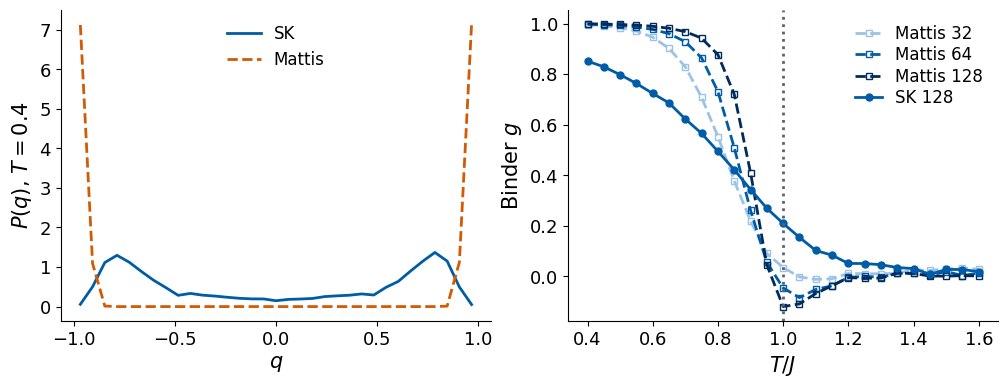

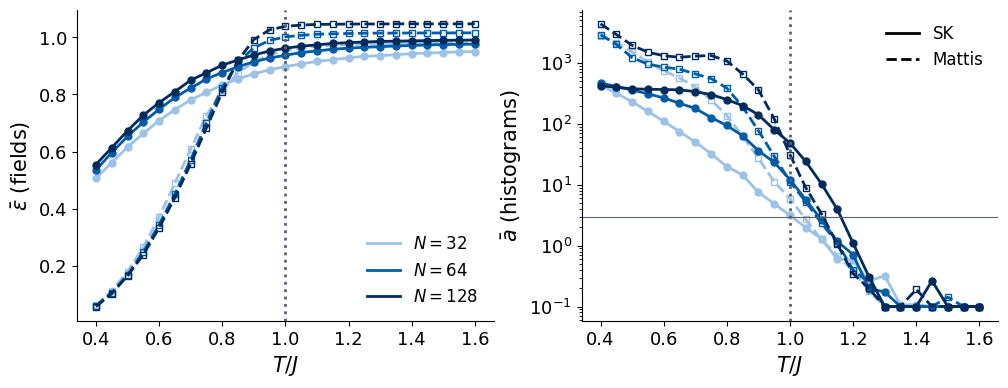

histogram score: values below 0.1 are drawn at 0.1 on the logarithmic axis


In [18]:
from matplotlib.lines import Line2D
fig, ax = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
qv = None
k = 0
for N in (128,):
    H_sk = np.stack([np.histogram(overlap_fields(sk[N]["configs"], [d], k, True).mean(1), bins=np.linspace(-1, 1, 34))[0]
                     for d in range(sk[N]["D"])]).mean(0)
    H_m = np.stack([np.histogram(overlap_fields(mattis[N], [d], k, True).mean(1), bins=np.linspace(-1, 1, 34))[0]
                    for d in range(mattis[N].shape[0])]).mean(0)
    centres = 0.5 * (np.linspace(-1, 1, 34)[1:] + np.linspace(-1, 1, 34)[:-1])
    width = 2 / 33
    ax[0].plot(centres, H_sk / H_sk.sum() / width, "-", color=UJBlue, label="SK")
    ax[0].plot(centres, H_m / H_m.sum() / width, "--", color=DSOrange, label="Mattis")
ax[0].set_xlabel("$q$"); ax[0].set_ylabel(r"$P(q)$, $T=0.4$"); ax[0].legend(loc="upper center")
for N in SIZES:
    ax[1].plot(T_GRID, binder(*mom_pca_m[N]), "s--", mfc="none", color=SIZE_COLORS[N])
ax[1].plot(T_GRID, binder(*mom_pca[128]), "o-", color=UJBlue)
ax[1].legend([Line2D([], [], color=SIZE_COLORS[N], ls="--", marker="s", mfc="none") for N in SIZES]
             + [Line2D([], [], color=UJBlue, marker="o")], [f"Mattis {N}" for N in SIZES] + ["SK 128"],
             loc="upper right", handlelength=1.6, labelspacing=0.2)
ax[1].axvline(T_C, color=UJGray, ls=":"); ax[1].set_xlabel("$T/J$"); ax[1].set_ylabel("Binder $g$")
fig.tight_layout(pad=0.3); savefig(fig, "gen_sk_ml_phys_mattis.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(FIG_W, FIG_H))
for N in SIZES:
    ax[0].plot(T_GRID, ae_q[N]["err"], "o-", color=SIZE_COLORS[N])
    ax[0].plot(T_GRID, ae_m[N]["err"], "s--", mfc="none", color=SIZE_COLORS[N])
    ax[1].semilogy(T_GRID, np.clip(score_sk[N].mean(0), 0.1, None), "o-", color=SIZE_COLORS[N])
    ax[1].semilogy(T_GRID, np.clip(score_m[N].mean(0), 0.1, None), "s--", mfc="none", color=SIZE_COLORS[N])
ax[0].set_ylabel(r"$\bar\varepsilon$ (fields)")
ax[1].axhline(3, color=UJGray, lw=0.8); ax[1].set_ylabel(r"$\bar a$ (histograms)")
ax[0].legend([Line2D([], [], color=SIZE_COLORS[N]) for N in SIZES], [f"$N={N}$" for N in SIZES], loc="lower right")
ax[1].legend([Line2D([], [], color="k"), Line2D([], [], color="k", ls="--")], ["SK", "Mattis"], loc="upper right")
for a in ax:
    a.axvline(T_C, color=UJGray, ls=":"); a.set_xlabel("$T/J$")
fig.tight_layout(pad=0.3); savefig(fig, "gen_sk_ml_mattis.png"); plt.show()
print("histogram score: values below 0.1 are drawn at 0.1 on the logarithmic axis")

The control behaves like a ferromagnet in the first two detectors. The Binder cumulant of the PCA projection rises to $1$ below $T_c$ (two sharp
peaks of $P(q)$ at $\pm m^2$, nothing in between), and the curves for different sizes cross at a well-defined point, with bootstrap intervals about ten
times narrower than for the SK model; the crossing moves towards $T_c=J$ as $N$ grows. The autoencoder error falls from about $1$ near $T_c$ to about
$0.06$ at $T=0.4$, which is $1-m^4$ with $m$ the Curie–Weiss magnetisation. In the SK model the Binder cumulant stays between $0.8$ and $0.85$ at the
lowest temperature (the weight between the peaks of $P(q)$), and the error decreases slowly and smoothly, only to about $0.5$.

The histogram detector behaves alike in both models: in the Mattis model, too, its alarm goes off above $T_c$, at a temperature that increases with $N$.
The Curie–Weiss transition is also a mean-field transition, with a susceptibility $1/(1-\beta J)$ that grows continuously as $T$ approaches $J$ from
above. The onset of an anomaly score measures where fluctuations become noticeable at the given resolution, not the critical temperature.

Both data sets have uniformly random single snapshots and both have random-sign couplings. The difference that the overlap-based detectors see,
a broad $P(q)$ that stays broad, is the signature of frustration.
<hr/>
## 5. Summary

| method | input | what it found | compared with the known physics |
|---|---|---|---|
| PCA | single snapshots | nothing with one snapshot per sample; growth of $\lambda_1$ below $T\approx1$ only through repeated snapshots of the same sample | gauge symmetry: pooled single snapshots are uniform at every $T$ |
| autoencoder | single snapshots | flat error on held-out samples; memorised frozen states of its training samples | frozen states are sample-specific |
| PCA | overlap fields $q_i=s_i^as_i^b$ | PC 1 is the uniform vector, $z_1=\sqrt N q$, $\lambda_1=N\overline{q^2}$ | the Edwards–Anderson overlap; Binder crossings as in Lab 032 |
| autoencoder, 1 latent number | overlap fields, trained on $T\le0.6$ | error $=1-q^2$ per pair; steepest change at $T=0.42$–$0.48$ for every $N$ | $q_{\rm EA}\propto(1-T/J)$: no edge at $T_c$ |
| autoencoder | histograms of $\lvert q\rvert$, trained on $T\ge1.3$ | onset of the anomaly above $T_c$, moving up with $N$ | growth of $\chi_{\rm SG}=1/(1-\beta^2J^2)$ above $T_c$ |
| all three | Mattis overlap fields | Binder $\to1$, sharp crossing; error $\to1-m^4$; histogram onset above $T_c$ as for SK | Curie–Weiss transition at $T_c=J$ |

The order of the spin glass is invisible in single snapshots, and no learning method can change this: the gauge symmetry makes the data uniform.
The right input, the overlap of two replicas, was found by physicists through the replica theory; given it, PCA finds the overlap as its first
component and the autoencoder learns $q^2$. Neither locates $T_c$ by itself. The PCA projection becomes a measurement of $T_c$ only through the
finite-size scaling of its Binder cumulant, with the same wide intervals as the physicist's analysis, and the anomaly onsets reflect the smooth
growth of fluctuations of a mean-field transition rather than its location. Supervised work on the three-dimensional Edwards–Anderson spin glass
reached the same conclusion about the input: Munoz-Bauza, Hamze and Katzgraber fed a convolutional network with replica overlap configurations,
not with spins.
<hr/>
## Exercises

### Exercise 1 — The covariance of an exchangeable distribution
Assume the pooled overlap fields have a distribution symmetric under permutations of the labels and under $\boldsymbol q\to-\boldsymbol q$.
(a) Show that the covariance matrix is $C=(1-c)\,\mathbb 1+c\,\boldsymbol 1\boldsymbol 1^T$ with $c=(N\overline{q^2}-1)/(N-1)$. (b) Find all eigenvalues.
(c) Compare with the PCA of Section 3.2 for $N=128$: $\lambda_1$ and the mean of the other eigenvalues.

#### Solution
(a) The diagonal entries are $\overline{q_i^2}=1$; by symmetry all off-diagonal entries are equal to $c$. Summing all entries,
$\sum_{ij}\overline{q_iq_j}=N^2\overline{q^2}=N+N(N-1)c$, which gives $c$. (b) $C\boldsymbol 1=(1-c+Nc)\boldsymbol 1$, so $\lambda_{\rm uniform}=1+(N-1)c=N\overline{q^2}$;
every vector orthogonal to $\boldsymbol 1$ has eigenvalue $1-c=N(1-\overline{q^2})/(N-1)$, $N-1$ times. (c) The code compares these with the measured spectrum.
Small differences in $\lambda_1$ come from the centring of PCA and the factor $M/(M-1)$; the other eigenvalues of the data scatter around their mean,
which is fixed by the trace, because the finite set of samples is only approximately exchangeable.

In [19]:
N = 128; lam = pca_q[N]["lam"]; q2 = pca_q[N]["q2_pooled"]
print(f"lambda_1 = {lam[0]:.3f},   N * mean(q^2) = {N * q2:.3f}")
print(f"mean of lambda_2..lambda_N = {lam[1:].mean():.4f},   N (1 - mean(q^2)) / (N - 1) = {N * (1 - q2) / (N - 1):.4f}")
print(f"spread of lambda_2..lambda_N: from {lam[1:].min():.3f} to {lam[1:].max():.3f}")

lambda_1 = 14.036,   N * mean(q^2) = 14.000
mean of lambda_2..lambda_N = 0.8974,   N (1 - mean(q^2)) / (N - 1) = 0.8976
spread of lambda_2..lambda_N: from 0.789 to 1.059


### Exercise 2 — A larger latent space
Train the overlap-field autoencoder for $N=32$ with 4 latent numbers instead of 1 (one fold is enough). Compare its mean error on held-out samples with
$1-[\langle q^2\rangle]$ at several temperatures, and print the ratio of the two. Does the extra capacity learn more physics?

#### Solution
With four numbers the error falls well below $1-[\langle q^2\rangle]$. A few real numbers can store part of the random positions of the
disagreeing spins of a 32-spin field, just as the single-snapshot autoencoder of Section 2.3 stored part of random strings. The ratio of the two
errors changes much less with temperature than $1-[\langle q^2\rangle]$ itself (printed below): the temperature dependence still enters through $q^2$.
The extra latent numbers compress noise, not a second order parameter.

In [20]:
N = 32; c = sk[N]["configs"]; tr, te = folds(sk[N]["D"])[0]
model4, _ = train_ae(flip_augment(np.concatenate([overlap_fields(c, tr, k) for k in np.where(LOW_T)[0]])), latent=4, epochs=60)
print("   T     error (4 latent)   1 - [q^2]   ratio")
for k in (0, 6, 12, 18, 24):
    X = overlap_fields(c, te, k, all_pairs=True)
    e = float(recon_error(model4, jnp.asarray(X)).mean())
    ref = 1 - (X.mean(1) ** 2).mean()
    print(f"{T_GRID[k]:5.2f}   {e:.3f}              {ref:.3f}       {e / ref:.3f}")

   T     error (4 latent)   1 - [q^2]   ratio


 0.40   0.357              0.504       0.710
 0.70   0.576              0.781       0.737


 1.00   0.676              0.898       0.753
 1.30   0.713              0.937       0.761


 1.60   0.727              0.952       0.764


<hr/>
## References

* D. Sherrington, S. Kirkpatrick, *Solvable model of a spin-glass*, Phys. Rev. Lett. **35**, 1792 (1975), [doi:10.1103/PhysRevLett.35.1792](https://doi.org/10.1103/PhysRevLett.35.1792)
* S. F. Edwards, P. W. Anderson, *Theory of spin glasses*, J. Phys. F **5**, 965 (1975), [doi:10.1088/0305-4608/5/5/017](https://doi.org/10.1088/0305-4608/5/5/017)
* D. C. Mattis, *Solvable spin systems with random interactions*, Phys. Lett. A **56**, 421 (1976), [doi:10.1016/0375-9601(76)90396-0](https://doi.org/10.1016/0375-9601(76)90396-0)
* A. Billoire, *Some aspects of infinite range models of spin glasses: theory and numerical simulations*, lecture notes, [arXiv:0709.1552](https://arxiv.org/abs/0709.1552)
* H. Nishimori, *Statistical Physics of Spin Glasses and Information Processing: An Introduction*, Oxford University Press (2001), [doi:10.1093/acprof:oso/9780198509417.001.0001](https://doi.org/10.1093/acprof:oso/9780198509417.001.0001)
* K. Kottmann, P. Huembeli, M. Lewenstein, A. Acín, *Unsupervised phase discovery with deep anomaly detection*, Phys. Rev. Lett. **125**, 170603 (2020), [arXiv:2003.09905](https://arxiv.org/abs/2003.09905)
* L. Wang, *Discovering phase transitions with unsupervised learning*, Phys. Rev. B **94**, 195105 (2016), [doi:10.1103/PhysRevB.94.195105](https://doi.org/10.1103/PhysRevB.94.195105)
* H. Munoz-Bauza, F. Hamze, H. G. Katzgraber, *Learning to find order in disorder*, J. Stat. Mech. (2020) 073302, [doi:10.1088/1742-5468/ab9e60](https://doi.org/10.1088/1742-5468/ab9e60), [arXiv:1903.06993](https://arxiv.org/abs/1903.06993)